# 04 · Variables · Cada idea es una apuesta que se mide

> **BORRADOR para revisión del grupo.** Cada cifra se calcula en este notebook, con **los mismos 5 pliegues** de la etapa 3, solo sobre el **entrenamiento**.
> La prueba cerrada **no se abre**. Lo marcado **[DECIDE EL GRUPO]** necesita una decisión de negocio; aquí va con una **propuesta** razonada para que el equipo la confirme o la cambie.
> El código reutilizable vive en `src/proyecto/features/engineering.py` y `src/proyecto/models/` (con pruebas en `tests/`); este notebook solo lo orquesta.

## Resumen para quien decide

| | Lo que se midió | Qué significa para el negocio |
|---|---|---|
| **1** | Con las variables que ya tenemos, un modelo de árboles (LightGBM) cuesta **0,325 unidades por cliente**, frente a **0,398** de la regla simple "llamar si hubo daño" | El modelo ya recorta **≈ 18 %** el costo de contacto frente a la mejor regla sin modelo |
| **2** | Se probaron 5 ideas para **agregar** variables (recorte de prima, segmento comercial, edad en curva, tasa histórica de región y canal, prima relativa a la región) | **Ninguna mejora al modelo de árboles.** Inventar variables no era el camino; lo que ya había alcanzaba |
| **3** | Para la **regresión logística**, un solo cambio, tratar la edad como curva, sube la PR-AUC de 0,337 a 0,356: **6 veces el ruido** y gana en los 5 pliegues | Hay un modelo **más simple de explicar** (regresión) que se acerca al de árboles si se le entrega bien la edad |
| **4** | Quitar `Vintage`, la licencia y el género **no cambia** el costo (0,3245 frente a 0,3252) | Se puede **acortar el formulario de la app** y retirar una variable sensible **sin pagar nada** |
| **5** | Quitar la prima **sí** empeora al modelo de árboles (1,1 veces el ruido) | La prima se **queda**, aunque por sí sola pareciera poco informativa |
| **6** | **Segunda ronda:** se conservaron las 10 variables y se crearon 6 derivadas (tamaño del canal, puntaje de necesidad, perfiles de 12 combinaciones, joven con vehículo nuevo, prima por edad, antigüedad relativa) | **Ninguna cumple la regla** (la mejor, +0,7 veces el ruido en la regresión) | La información útil **ya está en las 10 variables**: mejorar exige **datos nuevos** (historial de contactos, vencimiento del seguro actual, siniestros), no más columnas derivadas |

**Propuesta de variables para el torneo (etapa 5):** las variables limpias de la etapa 3 **sin** `Vintage`, `Driving_License` ni `Gender`, con los canales raros agrupados; y, solo para la regresión logística, la edad como curva.

## 0. Cargar el entrenamiento y fijar la validación

**Regla de la etapa:** todo lo que *aprende* de los datos (percentiles, canales raros, tasas por canal, escalas) va **dentro del `Pipeline`** y se ajusta **solo con el entrenamiento de cada pliegue**. Así ninguna cifra de este notebook se infla con información que el modelo no habría tenido.

In [1]:
import sys
import time
import warnings
from io import BytesIO
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate

from proyecto.data import split as sp
from proyecto.data.loading import load_train
from proyecto.features.engineering import FeatureOptions, PremiumClipper, build_preprocessor
from proyecto.models.metrics import COST_FALSE_NEGATIVE, cost_per_client, decision_threshold, make_scoring
from proyecto.models.train import build_pipeline, reference_models

TARGET = "Response"
BLUE, ORANGE, GRAY, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})

train = load_train(ROOT)                      # solo entrenamiento: la prueba cerrada no se carga
X, y = train.drop(columns=[TARGET]), train[TARGET]
folds = sp.stratified_folds(train, n_splits=5)   # los MISMOS pliegues de la etapa 3, para todo lo que se compare

# Comprobaciones de la validación común
for tr_idx, va_idx in folds:
    assert set(tr_idx).isdisjoint(set(va_idx))
assert sorted(np.concatenate([va for _, va in folds])) == list(range(len(train)))
print(f"Entrenamiento: {len(train):,} clientes, tasa de aceptación {y.mean():.3%}.")
print(f"{len(folds)} pliegues estratificados; cada cliente se valida una vez. Compradores por pliegue: {[int(y.iloc[va].sum()) for _, va in folds]}")
print(f"Umbral de decisión con R = {COST_FALSE_NEGATIVE:g}: llamar si la probabilidad supera {decision_threshold():.1%}.")

Entrenamiento: 304,887 clientes, tasa de aceptación 12.256%.
5 pliegues estratificados; cada cliente se valida una vez. Compradores por pliegue: [7474, 7474, 7473, 7473, 7474]
Umbral de decisión con R = 5: llamar si la probabilidad supera 16.7%.


## 1. Antes de medir: las apuestas y las reglas

Cada idea es una **hipótesis de negocio** con un costo operativo. Se escribe **antes** de medirla para no ajustar el criterio al resultado.

### 1.1 Las ideas

| # | Idea (cómo se calcula) | Por qué podría ayudar al negocio | ¿Se conoce al llamar? | Qué tendría que pedir o mantener la app |
|---|---|---|---|---|
| **1** | **Recorte de la prima** en el percentil 99 del entrenamiento | Unos pocos clientes con primas extremas (máx. 540.165 frente a un percentil 99 de 73.132) podrían distorsionar al modelo | Sí | Nada nuevo: guarda un número (el corte) |
| **2** | **Segmento comercial**: 1 si el cliente *no tiene seguro y sí tuvo daño* | Ese segmento concentra el 97,7 % de los compradores; el equipo comercial ya piensa en esos términos | Sí | Nada nuevo: se calcula con dos respuestas que ya se piden |
| **3** | **Edad como curva suave** (*splines*) | La aceptación sube hasta los 36-45 años y baja después; una recta no la representa | Sí | Nada nuevo |
| **4** | **Tasa histórica de región y canal** (porcentaje de aceptación del canal, aprendido del pasado) en vez de una columna 0/1 por canal | Resume en un número "qué tan bien vende este canal" y evita decenas de columnas | Sí, **si** la tabla histórica se mantiene al día | Una tabla de tasas por canal y región que alguien debe **actualizar** |
| **5** | **Prima relativa a su región** (prima dividida entre la mediana de su región) | Responde "¿este cliente paga más o menos que sus vecinos?" | Sí | La mediana por región, a mantener |
| **6** | **Quitar `Vintage` y `Driving_License`** | En el EDA no mostraron relación con la respuesta; menos preguntas en el formulario | — | Un campo menos en la app |
| **7** | **Quitar `Gender`** | Reduce el riesgo de **discriminación** y de reclamos regulatorios; si no cuesta nada, no hay razón para usarlo | — | Un campo menos en la app |
| **8** | **No agrupar los canales raros** (prueba de la decisión 5 del EDA) | Verifica que agrupar los 99 canales de menos de 100 clientes no hace perder información | Sí | Agrupar da robustez ante canales nuevos |
| **9** | **Quitar la prima y su marca** | La prima aporta poco por sí sola y es un dato que el cliente debe conocer y declarar | — | Un campo menos (y uno de los más delicados) |

### 1.2 La regla de decisión (escrita antes de medir)

**Propuesta para el equipo [DECIDE EL GRUPO: confirmar o ajustar]:**

| Regla | Texto | Por qué conviene |
|---|---|---|
| **R1 · Evidencia** | Una idea para **agregar** se conserva solo si su **mejora / ruido > 1** en la métrica principal (PR-AUC) **y** gana en **4 de los 5 pliegues** | Una mejora dentro del ruido puede desaparecer con otra partición; exigir 4 de 5 evita premiar la suerte |
| **R2 · Disponibilidad** | La variable debe conocerse **en el momento de llamar** | Si no, es fuga de información: el modelo sería inútil en la práctica |
| **R3 · Costo de complejidad** | No se agrega un dato que el equipo comercial no pueda dar o mantener, salvo que la evidencia sea muy clara (mejora / ruido > 3) | Cada variable nueva es una promesa operativa permanente |
| **R4 · Retiro** | Una variable se **retira** si quitarla empeora **menos de 1 ruido** (mejora / ruido ≥ -1) | "Sin costo medible" es razón suficiente para simplificar |
| **R5 · Equidad** | Las variables sensibles (`Gender`) se retiran cuando no cuestan nada; **nunca** se agregan para ganar precisión | El beneficio es menor que el riesgo legal y reputacional |

**Cómo se mide:** mejora / ruido = (métrica de la variante − métrica de la referencia) ÷ desviación entre pliegues de la variante. **PR-AUC** es la métrica principal (decide qué variables entran); el **costo por cliente** (R = 5, ver notebook 01) es la métrica de negocio; **log loss** y **ROC-AUC** son de control.

## 2. El pipeline y los dos modelos de referencia

Se usan **dos modelos de parámetros fijos**, no para ganar un torneo sino para entender qué variables aportan:
- **LightGBM** (árboles): captura solo interacciones y curvas. Si una variable nueva no lo mejora, es que el modelo ya la "descubría".
- **Regresión logística** (lineal): solo ve relaciones rectas. Es donde las variables nuevas **más** pueden ayudar, y además es la más fácil de explicar a un directivo.

In [2]:
models = reference_models()
base = FeatureOptions()
print("Variables que entran al modelo (referencia):")
names = build_pipeline(clone(models["lightgbm"]), base).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]]).named_steps["features"].get_feature_names_out()
print(f"  {len(names)} columnas tras el preprocesamiento. Primeras 12:", list(names[:12]))
print("  'id' y 'Response' nunca son variables:", "id" not in names and TARGET not in names)
print()
print("Pipeline de la referencia:")
print(build_pipeline(clone(models["lightgbm"]), base))

Variables que entran al modelo (referencia):


  112 columnas tras el preprocesamiento. Primeras 12: ['Age', 'Vintage', 'Vehicle_Age', 'Driving_License', 'Previously_Insured', 'Vehicle_Damage', 'Premium_is_minimum', 'Annual_Premium', 'Gender_Female', 'Gender_Male', 'Region_Code_0', 'Region_Code_1']
  'id' y 'Response' nunca son variables: True

Pipeline de la referencia:
Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('numeric', 'passthrough',
                                                  ['Age', 'Vintage',
                                                   'Vehicle_Age']),
                                                 ('binary', 'passthrough',
                                                  ['Driving_License',
                                                   'Previously_Insured',
                                                   'Vehicle_Damage',
                                                   'Premium_is_minimum']),
                                                 ('premium',
        

## 3. El experimento

Cada variante cambia **una sola cosa** respecto de la referencia. Mismo modelo, mismos pliegues, mismas métricas. Tarda varios minutos: son 5 ajustes por variante.

In [3]:
PRIMA = ("Annual_Premium", "Premium_is_minimum")
RUIDO = ("Vintage", "Driving_License")

# nombre -> (opciones, modelos en los que se mide)
VARIANTS = {
    "referencia": (base, "ambos"),
    "1 recorte de la prima (p99)": (base.with_changes(clip_premium=True), "ambos"),
    "2 segmento comercial": (base.with_changes(segment_flag=True), "ambos"),
    "3 edad como curva": (base.with_changes(age_splines=True), "ambos"),
    "4 tasa histórica de región y canal": (base.with_changes(target_encode_codes=True), "ambos"),
    "5 prima relativa a la región": (base.with_changes(premium_vs_region=True), "ambos"),
    "6 sin Vintage ni Driving_License": (base.with_changes(drop=RUIDO), "ambos"),
    "7 sin Gender": (base.with_changes(drop=("Gender",)), "ambos"),
    "8 sin agrupar canales raros": (base.with_changes(group_rare=False), "ambos"),
    "9 sin prima ni su marca": (base.with_changes(drop=PRIMA), "ambos"),
    "A simple: sin Vintage, licencia ni Gender": (base.with_changes(drop=RUIDO + ("Gender",)), "ambos"),
    "B mínima: A y sin prima": (base.with_changes(drop=RUIDO + ("Gender",) + PRIMA), "ambos"),
    "C: A + edad como curva": (base.with_changes(drop=RUIDO + ("Gender",), age_splines=True), "regresion_logistica"),
    "D: B + edad como curva": (base.with_changes(drop=RUIDO + ("Gender",) + PRIMA, age_splines=True), "regresion_logistica"),
}
scoring = make_scoring()
results = {}

t_start = time.time()
for model_name, model in models.items():
    for variant, (options, applies_to) in VARIANTS.items():
        if applies_to != "ambos" and applies_to != model_name:
            continue
        options = options.with_changes(scale=(model_name == "regresion_logistica"))   # la regresión necesita variables escaladas
        pipe = build_pipeline(clone(model), options)
        res = cross_validate(pipe, X, y, cv=folds, scoring=scoring, n_jobs=1)
        frame = pd.DataFrame({k.replace("test_", ""): v for k, v in res.items() if k.startswith("test_")})
        frame["cost"] = -frame["cost"]            # scikit-learn devuelve el costo con signo negativo
        frame["log_loss"] = -frame["log_loss"]
        results[(model_name, variant)] = frame
print(f"{len(results)} combinaciones medidas en {(time.time() - t_start) / 60:.1f} minutos.")

26 combinaciones medidas en 6.5 minutos.


## 4. Mejora sobre ruido, idea por idea

**Cómo leer la tabla:** `PR-AUC` y `costo` con su `± ruido` (desviación entre los 5 pliegues). **`mejora / ruido`:** cuántas veces el ruido supera la diferencia con la referencia. Por encima de **+1** hay mejora creíble; entre **-1 y +1** es indistinguible del azar; por debajo de **-1** la variante empeora de verdad.
`gana` cuenta en cuántos de los 5 pliegues la variante supera a la referencia en PR-AUC. Para el costo, **menos es mejor**: una `mejora` positiva significa que baja el costo.

In [4]:
def improvement_over_noise(reference, variant, lower_is_better=False):
    '''Mejora de la variante frente a la referencia, el ruido entre pliegues y su cociente (positivo = la variante mejora).'''
    gain = (reference.mean() - variant.mean()) if lower_is_better else (variant.mean() - reference.mean())
    noise = variant.std(ddof=1)
    return gain, noise, (gain / noise if noise > 0 else np.inf)

def summary_table(model_name):
    ref = results[(model_name, "referencia")]
    rows = []
    for (m, variant), frame in results.items():
        if m != model_name:
            continue
        g_pr, n_pr, r_pr = improvement_over_noise(ref["pr_auc"], frame["pr_auc"])
        g_c, n_c, r_c = improvement_over_noise(ref["cost"], frame["cost"], lower_is_better=True)
        rows.append({"variante": variant, "PR-AUC": frame["pr_auc"].mean(), "± ruido": n_pr, "mejora / ruido (PR-AUC)": r_pr,
                     "gana (de 5)": int((frame["pr_auc"].to_numpy() > ref["pr_auc"].to_numpy()).sum()),
                     "costo": frame["cost"].mean(), "mejora / ruido (costo)": r_c,
                     "log loss": frame["log_loss"].mean(), "ROC-AUC": frame["roc_auc"].mean()})
    table = pd.DataFrame(rows).set_index("variante")
    table.loc["referencia", ["mejora / ruido (PR-AUC)", "mejora / ruido (costo)"]] = 0.0
    return table

tables = {m: summary_table(m) for m in models}
fmt = {"PR-AUC": "{:.4f}", "± ruido": "{:.4f}", "mejora / ruido (PR-AUC)": "{:+.2f}", "costo": "{:.4f}",
       "mejora / ruido (costo)": "{:+.2f}", "log loss": "{:.4f}", "ROC-AUC": "{:.4f}"}
print("LightGBM (árboles)")
display(tables["lightgbm"].style.format(fmt))
print("Regresión logística (lineal)")
display(tables["regresion_logistica"].style.format(fmt))

LightGBM (árboles)


,PR-AUC,± ruido,mejora / ruido (PR-AUC),gana (de 5),costo,mejora / ruido (costo),log loss,ROC-AUC
variante,,,,,,,,
referencia,0.3715,0.0036,+0.00,0,0.3252,+0.00,0.2645,0.8580
1 recorte de la prima (p99),0.3710,0.0031,-0.15,1,0.3254,-0.07,0.2646,0.8580
2 segmento comercial,0.3706,0.0037,-0.24,0,0.3257,-0.16,0.2645,0.8581
3 edad como curva,0.3694,0.0034,-0.62,0,0.3252,+0.00,0.2647,0.8578
4 tasa histórica de región y canal,0.3709,0.0044,-0.12,2,0.3274,-0.57,0.2651,0.8571
5 prima relativa a la región,0.3709,0.0032,-0.17,1,0.3251,+0.02,0.2646,0.8580
6 sin Vintage ni Driving_License,0.3706,0.0035,-0.25,1,0.3252,+0.00,0.2645,0.8579
7 sin Gender,0.3698,0.0036,-0.46,0,0.3257,-0.16,0.2647,0.8577
8 sin agrupar canales raros,0.3712,0.0034,-0.07,2,0.3254,-0.06,0.2645,0.8581


Regresión logística (lineal)


,PR-AUC,± ruido,mejora / ruido (PR-AUC),gana (de 5),costo,mejora / ruido (costo),log loss,ROC-AUC
variante,,,,,,,,
referencia,0.3369,0.0034,+0.00,0,0.3327,+0.00,0.2689,0.8492
1 recorte de la prima (p99),0.3370,0.0035,+0.02,3,0.3328,-0.05,0.2689,0.8492
2 segmento comercial,0.3370,0.0035,+0.01,2,0.3330,-0.13,0.2689,0.8492
3 edad como curva,0.3562,0.0031,+6.20,5,0.3272,+2.35,0.2665,0.8544
4 tasa histórica de región y canal,0.3271,0.0045,-2.16,0,0.3355,-0.83,0.2715,0.8444
5 prima relativa a la región,0.3371,0.0035,+0.06,4,0.3329,-0.10,0.2688,0.8492
6 sin Vintage ni Driving_License,0.3372,0.0033,+0.09,5,0.3332,-0.18,0.2689,0.8491
7 sin Gender,0.3369,0.0033,+0.00,3,0.3336,-0.40,0.2689,0.8492
8 sin agrupar canales raros,0.3372,0.0035,+0.08,4,0.3330,-0.11,0.2688,0.8492


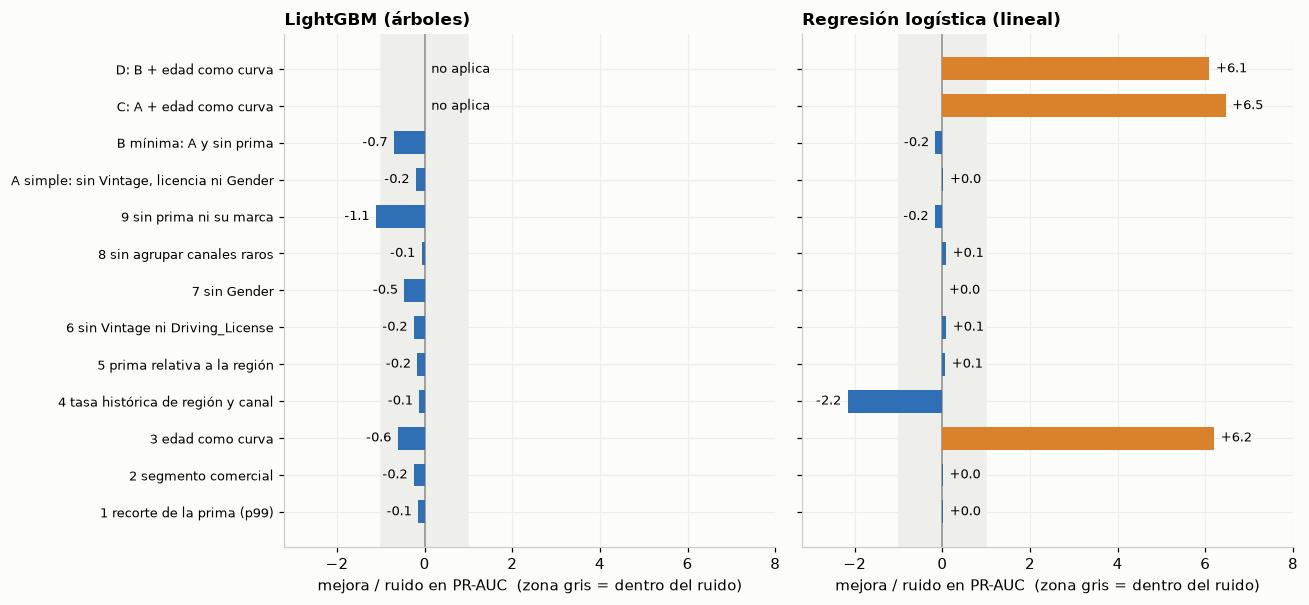

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
order = [v for v in VARIANTS if v != "referencia"]
for ax, (model_name, title) in zip(axes, [("lightgbm", "LightGBM (árboles)"), ("regresion_logistica", "Regresión logística (lineal)")]):
    t = tables[model_name]
    vals = [t.loc[v, "mejora / ruido (PR-AUC)"] if v in t.index else np.nan for v in order]
    ax.axvspan(-1, 1, color="#eeeeea", zorder=0)
    ax.axvline(0, color=GRAY, lw=1)
    colors = [ORANGE if (v == v and v > 1) else BLUE for v in vals]
    ax.barh(range(len(order)), [0 if np.isnan(v) else v for v in vals], color=colors, height=0.62, zorder=2)
    for i, v in enumerate(vals):
        ax.text((0 if np.isnan(v) else v) + (0.15 if (np.isnan(v) or v >= 0) else -0.15), i, "no aplica" if np.isnan(v) else f"{v:+.1f}",
                va="center", ha="left" if (np.isnan(v) or v >= 0) else "right", fontsize=8.5)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8.5)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("mejora / ruido en PR-AUC  (zona gris = dentro del ruido)")
    ax.set_xlim(-3.2, 8)
plt.tight_layout()
plt.show()

### 4.1 Lectura del experimento

**LightGBM (árboles): ninguna idea mejora la referencia.**
- Las cinco ideas para **agregar** variables quedan entre **-0,6 y -0,1** veces el ruido: ninguna supera el umbral de +1 y ninguna gana en más de 2 de los 5 pliegues. El modelo de árboles ya descubría solo lo que esas variables le querían explicar (interacciones, curvas, tramos).
- **Idea 4 (tasa histórica de canal y región):** además de no mejorar, es la que **más empeora el costo** (0,3274 frente a 0,3252) y la **única que obliga a mantener una tabla externa**. Es la peor relación beneficio / costo operativo.
- **Idea 3 (edad como curva):** -0,6. A los árboles les da igual: ya parten la edad donde convenga.

**Regresión logística: una idea cambia el juego.**
- **Idea 3 (edad como curva) sube la PR-AUC de 0,337 a 0,356 (+6,2 veces el ruido), gana en los 5 pliegues, baja el costo (0,3327 → 0,3272) y mejora el log loss.** La razón es la que mostró el EDA: la aceptación dibuja una campana con la edad (3,5 % → 21,5 % → 8,3 %) y una recta no la representa.
- **Idea 4 (tasa histórica) empeora a la regresión** (-2,2 veces el ruido): una explicación plausible (por verificar) es que reemplaza más de cien columnas por solo dos números y le quita flexibilidad a un modelo que necesita esa flexibilidad.
- Las demás ideas quedan en el ruido (entre -0,2 y +0,1).

**Retirar variables:**
- **Idea 6 (sin `Vintage` ni licencia):** -0,25 en árboles y +0,09 en regresión: **sin efecto medible**. Cumple la regla R4 (≥ -1) y simplifica.
- **Idea 7 (sin `Gender`):** -0,46 en árboles (dentro del ruido; costo 0,3257 frente a 0,3252) y 0,0 en regresión. **Retirar el género no cuesta nada medible**: cumple R4 y R5.
- **Idea 9 (sin prima ni su marca):** **-1,11 en árboles** y 0 de 5 pliegues ganados: **empeora de verdad**. Esto contradice la intuición del EDA (la prima parecía poco informativa por sí sola, 0,35 %): un modelo de árboles **sí la usa**, probablemente combinada con otras variables. **La prima se queda.** En la regresión no importa (-0,17).
- **Idea 8 (sin agrupar canales raros):** -0,07 y +0,08: es **neutra**. Agrupar los 99 canales raros no hace perder información, y da robustez ante canales nuevos. Se conserva la agrupación.

## 5. ¿Las variantes ganan de forma consistente, o es promedio engañoso?

El promedio puede esconder que una variante gana por mucho en un pliegue y pierde en los demás. Se compara **pliegue por pliegue**.

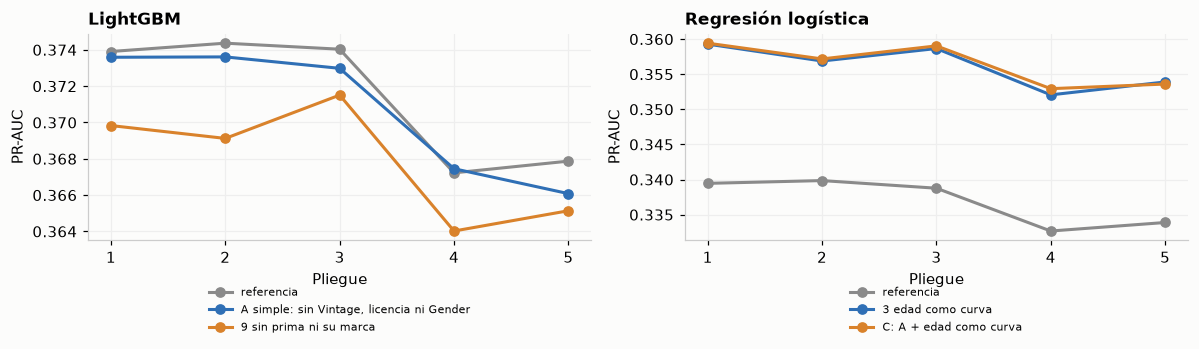

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
specs = [("lightgbm", ["referencia", "A simple: sin Vintage, licencia ni Gender", "9 sin prima ni su marca"], "LightGBM"),
         ("regresion_logistica", ["referencia", "3 edad como curva", "C: A + edad como curva"], "Regresión logística")]
palette = [GRAY, BLUE, ORANGE]
for ax, (model_name, variants, title) in zip(axes, specs):
    for variant, color in zip(variants, palette):
        ax.plot(range(1, 6), results[(model_name, variant)]["pr_auc"], marker="o", color=color, lw=2, ms=6, label=variant)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("Pliegue")
    ax.set_ylabel("PR-AUC")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, -0.5))
plt.tight_layout()
plt.show()

**Lectura:** en la regresión logística, las líneas de "edad como curva" quedan **por encima de la referencia en los 5 pliegues, sin cruzarse**: la mejora es consistente, no un promedio engañoso. En LightGBM, la referencia y la versión simple (sin `Vintage`, licencia ni género) **se superponen**: son estadísticamente la misma. La línea sin prima queda **por debajo en todos los pliegues**, de forma sistemática aunque pequeña.

## 6. Comprobaciones de que no hay fuga de información

Con tasas históricas por canal (idea 4) es donde más fácil se filtra la respuesta al modelo. Se verifican dos cosas.

**a) Las cosas que "aprenden" se ajustan con cada pliegue por separado.** Si el recorte de la prima se calculara una sola vez con todos los datos, el corte sería el mismo en cada pliegue.

In [7]:
cuts = [PremiumClipper().fit(X.iloc[tr][["Annual_Premium"]]).upper_ for tr, _ in folds]
print("Percentil 99 de la prima aprendido en cada pliegue:", [f"{c:,.0f}" for c in cuts])
print(f"Percentil 99 de TODO el entrenamiento:            {X['Annual_Premium'].quantile(0.99):,.0f}")
print("Distintos entre pliegues:", len(set(np.round(cuts, 3))) > 1, "-> cada pliegue aprende lo suyo, solo con sus datos de entrenamiento.")

Percentil 99 de la prima aprendido en cada pliegue: ['73,021', '73,221', '73,176', '73,080', '73,221']
Percentil 99 de TODO el entrenamiento:            73,132
Distintos entre pliegues: True -> cada pliegue aprende lo suyo, solo con sus datos de entrenamiento.


**b) Prueba de etiquetas barajadas.** Si se mezclan al azar las respuestas, las variables ya no pueden predecirlas. Un pipeline limpio debe entonces dar una PR-AUC **cercana a la proporción de compradores** (≈ 0,1226). Si diera mucho más, estaría filtrando la respuesta.

In [8]:
y_shuffled = y.sample(frac=1.0, random_state=0).to_numpy()     # respuestas sin relación con las variables
checks = {}
for label, options in [("referencia", base), ("4 tasa histórica de región y canal", base.with_changes(target_encode_codes=True))]:
    res = cross_validate(build_pipeline(clone(models["lightgbm"]), options), X, y_shuffled, cv=folds,
                         scoring={"pr_auc": "average_precision"}, n_jobs=1)
    checks[label] = res["test_pr_auc"]

display(pd.DataFrame({"PR-AUC con etiquetas barajadas": {k: v.mean() for k, v in checks.items()},
                      "máximo en un pliegue": {k: v.max() for k, v in checks.items()}}).round(4))
print(f"Proporción de compradores (lo esperable por azar): {y.mean():.4f}")
assert all(v.mean() < y.mean() + 0.01 for v in checks.values()), "posible fuga de información"
print("Sin fuga: con etiquetas sin relación, el pipeline no predice mejor que el azar, ni siquiera con tasas históricas.")

,PR-AUC con etiquetas barajadas,máximo en un pliegue
referencia,0.1229,0.1252
4 tasa histórica de región y canal,0.1223,0.1237


Proporción de compradores (lo esperable por azar): 0.1226
Sin fuga: con etiquetas sin relación, el pipeline no predice mejor que el azar, ni siquiera con tasas históricas.


**Lectura:** con las respuestas barajadas, ambos pipelines quedan en ≈ 0,123, **la proporción de compradores**. La tasa histórica de canal y región (la idea más expuesta a fuga) está bien aislada, porque `TargetEncoder` calcula las tasas con validación cruzada interna y dentro de cada pliegue. Los resultados del experimento **no están inflados**.

## 7. ¿Qué variables usa realmente el modelo?

Se mide cuánto **cae la PR-AUC** al desordenar al azar cada variable (importancia por permutación) en el pliegue 1, con el modelo ajustado solo con su entrenamiento. Es la contraparte del ranking del EDA, medida ahora sobre el modelo.

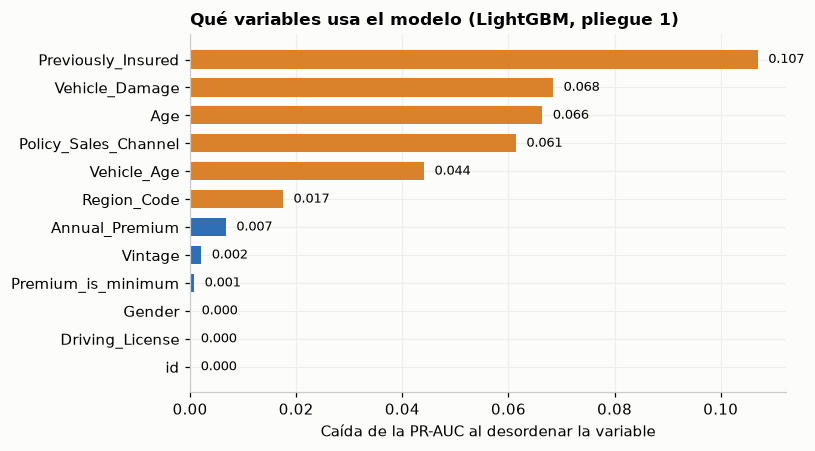

Importancia de 'id' (debe ser 0: el pipeline no la usa): 0.0
El pipeline completo se puede guardar con joblib: 0.7 MB (la app cargará un solo objeto).


In [9]:
tr0, va0 = folds[0]
pipe_ref = build_pipeline(clone(models["lightgbm"]), base).fit(X.iloc[tr0], y.iloc[tr0])
imp = permutation_importance(pipe_ref, X.iloc[va0], y.iloc[va0], scoring="average_precision", n_repeats=3, random_state=42, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(importance.index, importance.to_numpy(), color=[ORANGE if v > 0.01 else BLUE for v in importance], height=0.65)
for i, v in enumerate(importance):
    ax.text(max(v, 0) + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlabel("Caída de la PR-AUC al desordenar la variable")
ax.set_title("Qué variables usa el modelo (LightGBM, pliegue 1)")
plt.tight_layout()
plt.show()
print("Importancia de 'id' (debe ser 0: el pipeline no la usa):", round(float(importance["id"]), 6))

buffer = BytesIO()
joblib.dump(pipe_ref, buffer)
print(f"El pipeline completo se puede guardar con joblib: {buffer.tell() / 1e6:.1f} MB (la app cargará un solo objeto).")

**Lectura:** el modelo se apoya sobre todo en `Previously_Insured` (0,107), `Vehicle_Damage` (0,068), `Age` (0,066) y `Policy_Sales_Channel` (0,061), con `Vehicle_Age` (0,044) cerca: **casi el mismo grupo que mostró el EDA**. La diferencia es que la edad sube un puesto y queda por encima del canal; es coherente con que su efecto tiene forma de curva y el EDA lo medía por tramos. `Annual_Premium` aparece con un peso **pequeño pero positivo** (0,007), coherente con la idea 9 (quitarla sí cuesta). `Gender` (0,0002), `Driving_License` (0,0000) y `Vintage` (0,002) pesan casi cero, coherente con que retirarlas no cuesta nada. `id` pesa exactamente cero: el pipeline la ignora, como debe.

## 8. De la mejora de precisión al valor para el negocio

Un número como "PR-AUC 0,371" no le dice nada a un directivo. Se traduce a **costo de contacto** (en unidades de llamada, donde 1 = una llamada que no vende) y a una campaña de tamaño concreto.

**Parámetros que el negocio debe confirmar:**
- `CLIENTES_POR_CAMPANA`: cuántos clientes se evalúan en una campaña típica. Se propone 100.000 como escala de referencia **[DECIDE EL GRUPO]**.
- `R = 5`: cuánto cuesta no llamar a un comprador frente a una llamada inútil (hipótesis del notebook 01) **[DECIDE EL GRUPO]**. Cambiarlo cambia las cifras absolutas, no el orden entre estrategias.

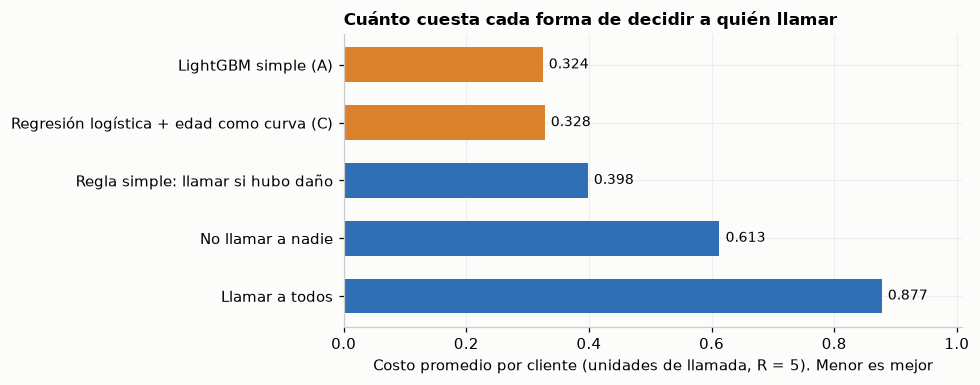

,costo por cliente,ahorro frente a la regla simple (por cliente),"ahorro por 100,000 clientes (unidades de llamada)",reducción del costo frente a la regla simple
LightGBM simple (A),0.3245,+0.0736,"+7,357",+18.5%
Regresión logística + edad como curva (C),0.3278,+0.0702,"+7,021",+17.6%
Regla simple: llamar si hubo daño,0.3980,+0.0000,+0,+0.0%
No llamar a nadie,0.6128,-0.2148,"-21,478",-54.0%
Llamar a todos,0.8774,-0.4794,"-47,940",-120.4%


Un 'ruido' de costo entre pliegues equivale a ≈ 309 unidades de llamada por 100,000 clientes: diferencias menores que eso no se distinguen del azar.


In [10]:
CLIENTES_POR_CAMPANA = 100_000      # [DECIDE EL GRUPO] tamaño de una campaña típica

def mean_cost(rule):
    '''Costo promedio por cliente de una regla fija, medido en los mismos 5 pliegues de validación.'''
    return float(np.mean([cost_per_client(y.iloc[va], rule(X.iloc[va])) for _, va in folds]))

strategies = pd.Series({
    "No llamar a nadie": mean_cost(lambda d: np.zeros(len(d), dtype=int)),
    "Llamar a todos": mean_cost(lambda d: np.ones(len(d), dtype=int)),
    "Regla simple: llamar si hubo daño": mean_cost(lambda d: d["Vehicle_Damage"].to_numpy()),
    "Regresión logística + edad como curva (C)": results[("regresion_logistica", "C: A + edad como curva")]["cost"].mean(),
    "LightGBM simple (A)": results[("lightgbm", "A simple: sin Vintage, licencia ni Gender")]["cost"].mean(),
}, name="costo por cliente").sort_values()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(strategies.index, strategies.to_numpy(), color=[ORANGE if "LightGBM" in s or "Regresión" in s else BLUE for s in strategies.index], height=0.6)
for i, v in enumerate(strategies):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, strategies.max() * 1.15)
ax.set_xlabel("Costo promedio por cliente (unidades de llamada, R = 5). Menor es mejor")
ax.set_title("Cuánto cuesta cada forma de decidir a quién llamar")
plt.tight_layout()
plt.show()

rule_cost = strategies["Regla simple: llamar si hubo daño"]
ahorro = pd.DataFrame({
    "costo por cliente": strategies,
    "ahorro frente a la regla simple (por cliente)": rule_cost - strategies,
    f"ahorro por {CLIENTES_POR_CAMPANA:,} clientes (unidades de llamada)": (rule_cost - strategies) * CLIENTES_POR_CAMPANA,
    "reducción del costo frente a la regla simple": (rule_cost - strategies) / rule_cost,
})
display(ahorro.style.format({"costo por cliente": "{:.4f}", "ahorro frente a la regla simple (por cliente)": "{:+.4f}",
                             f"ahorro por {CLIENTES_POR_CAMPANA:,} clientes (unidades de llamada)": "{:+,.0f}",
                             "reducción del costo frente a la regla simple": "{:+.1%}"}))

noise_cost = results[("lightgbm", "referencia")]["cost"].std(ddof=1)
print(f"Un 'ruido' de costo entre pliegues equivale a ≈ {noise_cost * CLIENTES_POR_CAMPANA:,.0f} unidades de llamada por {CLIENTES_POR_CAMPANA:,} clientes: "
      "diferencias menores que eso no se distinguen del azar.")

**Lectura de negocio:**
- **El modelo vale la pena.** Frente a la mejor regla sin modelo ("llamar si hubo daño"), el LightGBM simple (A) reduce el costo **18,5 %**: unas **7.400 unidades de llamada por cada 100.000 clientes evaluados** (la regresión con edad en curva, 17,6 % y unas 7.000). La regla ya es buena (cuesta 0,398 frente a 0,613 de no llamar a nadie), pero el modelo **ordena dentro del segmento clave**, que es lo que la regla no puede hacer.
- **El modelo sencillo (regresión + edad como curva) recupera casi todo el valor:** cuesta 0,328 frente a 0,3245 de los árboles, una diferencia de ≈ 340 unidades por 100.000 clientes, **comparable al ruido** (≈ 310). Si el negocio valora la **explicabilidad** (poder decir "la probabilidad sube con X y baja con Y"), la regresión es una opción seria. Los árboles ganan en PR-AUC (0,371 frente a 0,356, unas 4 veces el ruido): ordenan algo mejor a los clientes.
- **Las ideas descartadas tampoco son un fracaso:** el costo de **no** haberlas medido habría sido mantener variables que no aportan, con datos adicionales que pedir y tablas que actualizar.

## 9. Decisiones

Cada idea con su cifra (mejora / ruido en PR-AUC), la decisión aplicando la regla de la sección 1.2 y **quién debe cerrarla**. Cópiala a `reports/04_features.md`.

| # | Idea | LightGBM | Reg. logística | Decisión | Motivo | Quién cierra |
|---|---|---|---|---|---|---|
| 1 | Recorte de la prima (p99) | -0,15 | +0,02 | **Descartar** | No supera +1 en ningún modelo. Los árboles ya son robustos a extremos | Datos |
| 2 | Segmento comercial | -0,24 | +0,01 | **Descartar** | Los modelos ya aprenden esa interacción solos (97,7 % de los compradores). Se conserva como **regla de contacto** de negocio, no como variable | Datos y Negocio |
| 3 | Edad como curva | -0,62 | **+6,20** | **Conservar solo para la regresión logística** | Cumple R1 (+6,2 y 5/5 pliegues). Para árboles no aporta | Datos |
| 4 | Tasa histórica de región y canal | -0,12 | **-2,16** | **Descartar** | Empeora la regresión, empeora el costo en árboles y obliga a mantener una tabla externa (R3) | Datos |
| 5 | Prima relativa a la región | -0,17 | +0,06 | **Descartar** | Dentro del ruido; exige mantener medianas por región (R3) | Datos |
| 6 | Sin `Vintage` ni `Driving_License` | -0,25 | +0,09 | **Retirar** | Sin costo medible (R4); dos preguntas menos en la app | Negocio |
| 7 | Sin `Gender` | -0,46 | 0,00 | **Retirar** | Sin costo medible y elimina una variable sensible (R4 y R5) | Negocio y Legal |
| 8 | No agrupar canales raros | -0,07 | +0,08 | **Mantener el agrupamiento** | Neutra en desempeño; el agrupamiento da robustez ante canales nuevos | Datos |
| 9 | Sin prima ni su marca | **-1,11** | -0,17 | **Conservar la prima** | En árboles empeora de verdad (0 de 5 pliegues); no cumple R4 | Datos y Negocio |

> **Una idea descartada con su cifra es un resultado, no un fracaso.** Las ideas 1, 2, 4 y 5 quedan registradas con su evidencia para no volver a probarlas sin una razón nueva.

### 9.1 Confirmar la combinación final

Las ideas se midieron **de una en una**. Falta confirmar que la combinación propuesta (A para árboles, C para regresión) rinde igual que la suma de sus partes.

In [11]:
def app_inputs(options):
    # Datos que la app debe pedir: columnas de entrada que usa el pipeline, sin las que se calculan solas (la marca de prima mínima)
    pre = build_preprocessor(options).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]])
    used = set()
    for name, _, columns in pre.transformers_:
        if name != "remainder":
            used |= set(columns)
    return len(used - {"Premium_is_minimum"})

final = [("LightGBM · referencia", "lightgbm", "referencia"),
         ("LightGBM · A (sin Vintage, licencia ni Gender)", "lightgbm", "A simple: sin Vintage, licencia ni Gender"),
         ("LightGBM · B (A y sin prima)", "lightgbm", "B mínima: A y sin prima"),
         ("Regresión · referencia", "regresion_logistica", "referencia"),
         ("Regresión · C (A + edad como curva)", "regresion_logistica", "C: A + edad como curva"),
         ("Regresión · D (B + edad como curva)", "regresion_logistica", "D: B + edad como curva")]
rows = []
for label, model_name, variant in final:
    ref = results[(model_name, "referencia")]
    frame = results[(model_name, variant)]
    _, _, ratio_pr = improvement_over_noise(ref["pr_auc"], frame["pr_auc"])
    rows.append({"variante": label, "PR-AUC": frame["pr_auc"].mean(), "± ruido": frame["pr_auc"].std(ddof=1),
                 "mejora / ruido": 0.0 if variant == "referencia" else ratio_pr, "costo": frame["cost"].mean(),
                 "datos que pide la app": app_inputs(VARIANTS[variant][0])})
display(pd.DataFrame(rows).set_index("variante").style.format({"PR-AUC": "{:.4f}", "± ruido": "{:.4f}", "mejora / ruido": "{:+.2f}", "costo": "{:.4f}"}))

,PR-AUC,± ruido,mejora / ruido,costo,datos que pide la app
variante,,,,,
LightGBM · referencia,0.3715,0.0036,+0.00,0.3252,10
"LightGBM · A (sin Vintage, licencia ni Gender)",0.3707,0.0037,-0.20,0.3245,7
LightGBM · B (A y sin prima),0.3691,0.0033,-0.70,0.3251,6
Regresión · referencia,0.3369,0.0034,+0.00,0.3327,10
Regresión · C (A + edad como curva),0.3564,0.0030,+6.46,0.3278,7
Regresión · D (B + edad como curva),0.3554,0.0030,+6.09,0.3281,6


**Lectura:** la versión simple **A** para árboles (PR-AUC 0,3707 frente a 0,3715) y la **C** para regresión (0,3564 frente a 0,3369) **conservan todo el rendimiento** con menos variables. **B** y **D** (sin la prima) pierden un poco: se descartan. La última columna muestra que las versiones propuestas **piden menos datos al usuario** que la referencia.

In [12]:
# Se guarda la tabla completa para el informe y para que el grupo pueda reproducirla
(ROOT / "reports").mkdir(exist_ok=True)
export = []
for (model_name, variant), frame in results.items():
    export.append({"modelo": model_name, "variante": variant, "pr_auc": frame["pr_auc"].mean(), "pr_auc_ruido": frame["pr_auc"].std(ddof=1),
                   "costo": frame["cost"].mean(), "costo_ruido": frame["cost"].std(ddof=1), "log_loss": frame["log_loss"].mean(),
                   "roc_auc": frame["roc_auc"].mean()})
pd.DataFrame(export).round(5).to_csv(ROOT / "reports" / "04_features_tabla.csv", index=False)
print("Guardado en reports/04_features_tabla.csv:", len(export), "filas.")

Guardado en reports/04_features_tabla.csv: 26 filas.


## 9.2 Segunda ronda: variables nuevas, conservando todas las que ya tenemos

Hasta aquí se probó **agregar o quitar** variables con ideas puntuales. Esta ronda hace otra pregunta: **si se conservan las 10 variables actuales y se crean variables derivadas, ¿el modelo mejora?** Aquí **no se retira nada**.
**Referencias:** LightGBM con las variables limpias; para la regresión, la referencia ya incluye la **edad como curva** (la única mejora que ganó antes), para no confundir los dos efectos.
Misma validación, mismos 5 pliegues, misma regla de decisión (sección 1.2).

| # | Variable nueva | Qué pregunta de negocio responde | Cómo se calcula | Columnas | ¿Se conoce al llamar? | Qué debe mantener la app |
|---|---|---|---|---|---|---|
| **N1** | Tamaño del canal y de la región | ¿Es un canal **masivo o de nicho**? | Logaritmo de cuántos clientes tiene cada canal y región en el entrenamiento | +2 | Sí | Una tabla de conteos (se reentrena con el modelo) |
| **N2** | Puntaje de necesidad de cobertura | ¿Qué tan **necesitado** de seguro está el cliente? | (no tiene seguro) + (tuvo daño) + antigüedad del vehículo (0 a 2): de 0 a 4 | +1 | Sí | Nada |
| **N3** | Perfil de 12 combinaciones | ¿En **cuál de los 12 perfiles** cae (seguro previo × daño × antigüedad)? | Código 0 a 11, una columna por perfil | +12 | Sí | Nada |
| **N4** | Joven con vehículo nuevo | ¿Es el cruce de **dos grupos que casi no compran**? | 25 años o menos **y** vehículo de menos de 1 año | +1 | Sí | Nada |
| **N5** | Prima frente a su tramo de edad | ¿Paga **más o menos** que sus pares de edad? | Prima ÷ mediana de la prima de su tramo de edad (del entrenamiento) | +1 | Sí | Las medianas por tramo |
| **N6** | Fracción de su vida como cliente | ¿Es un cliente **antiguo para su edad**? | `Vintage` ÷ (edad × 365,25) | +1 | Sí | Nada |

**Ninguna usa la respuesta**: se calculan solo con datos que el vendedor tiene antes de llamar. Las pruebas automáticas verifican que, con la respuesta barajada, las seis quedan idénticas.

In [13]:
NEW_LABELS = {"channel_region_volume": "N1 tamaño del canal y la región", "need_score": "N2 puntaje de necesidad",
              "profile_12": "N3 perfil de 12 combinaciones", "young_new_vehicle": "N4 joven con vehículo nuevo",
              "premium_vs_age_band": "N5 prima frente a su tramo de edad", "vintage_share": "N6 fracción de vida como cliente"}
refs2 = {"lightgbm": base, "regresion_logistica": base.with_changes(age_splines=True)}
results2 = {}
added_columns = {}

t_start = time.time()
for model_name, model in models.items():
    ref_options = refs2[model_name]
    variants2 = {"referencia": ref_options}
    variants2.update({label: ref_options.with_changes(**{name: True}) for name, label in NEW_LABELS.items()})
    variants2["todas las nuevas"] = ref_options.with_all_new()
    n_ref = len(build_preprocessor(ref_options).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]]).get_feature_names_out())
    for variant, options in variants2.items():
        options = options.with_changes(scale=(model_name == "regresion_logistica"))
        n_cols = len(build_preprocessor(options).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]]).get_feature_names_out())
        added_columns[(model_name, variant)] = n_cols - n_ref
        res = cross_validate(build_pipeline(clone(model), options), X, y, cv=folds, scoring=scoring, n_jobs=1)
        frame = pd.DataFrame({k.replace("test_", ""): v for k, v in res.items() if k.startswith("test_")})
        frame["cost"], frame["log_loss"] = -frame["cost"], -frame["log_loss"]
        results2[(model_name, variant)] = frame
print(f"{len(results2)} combinaciones medidas en {(time.time() - t_start) / 60:.1f} minutos.")

def summary_from(res_dict, model_name):
    ref = res_dict[(model_name, "referencia")]
    rows = []
    for (m, variant), frame in res_dict.items():
        if m != model_name:
            continue
        _, noise, ratio_pr = improvement_over_noise(ref["pr_auc"], frame["pr_auc"])
        _, _, ratio_cost = improvement_over_noise(ref["cost"], frame["cost"], lower_is_better=True)
        rows.append({"variante": variant, "columnas que agrega": added_columns[(m, variant)], "PR-AUC": frame["pr_auc"].mean(), "± ruido": noise,
                     "mejora / ruido (PR-AUC)": 0.0 if variant == "referencia" else ratio_pr,
                     "gana (de 5)": int((frame["pr_auc"].to_numpy() > ref["pr_auc"].to_numpy()).sum()),
                     "costo": frame["cost"].mean(), "mejora / ruido (costo)": 0.0 if variant == "referencia" else ratio_cost,
                     "log loss": frame["log_loss"].mean()})
    return pd.DataFrame(rows).set_index("variante")

tables2 = {m: summary_from(results2, m) for m in models}
fmt2 = {"PR-AUC": "{:.4f}", "± ruido": "{:.4f}", "mejora / ruido (PR-AUC)": "{:+.2f}", "costo": "{:.4f}",
        "mejora / ruido (costo)": "{:+.2f}", "log loss": "{:.4f}"}
print("LightGBM (árboles), referencia = variables limpias")
display(tables2["lightgbm"].style.format(fmt2))
print("Regresión logística, referencia = variables limpias + edad como curva")
display(tables2["regresion_logistica"].style.format(fmt2))

16 combinaciones medidas en 5.2 minutos.
LightGBM (árboles), referencia = variables limpias


,columnas que agrega,PR-AUC,± ruido,mejora / ruido (PR-AUC),gana (de 5),costo,mejora / ruido (costo),log loss
variante,,,,,,,,
referencia,0,0.3715,0.0036,+0.00,0,0.3252,+0.00,0.2645
N1 tamaño del canal y la región,2,0.3707,0.0025,-0.33,2,0.3248,+0.11,0.2645
N2 puntaje de necesidad,1,0.3708,0.0031,-0.22,1,0.3256,-0.12,0.2646
N3 perfil de 12 combinaciones,12,0.3712,0.0044,-0.07,1,0.3249,+0.09,0.2645
N4 joven con vehículo nuevo,1,0.3715,0.0037,-0.00,2,0.3252,+0.01,0.2645
N5 prima frente a su tramo de edad,1,0.3707,0.0037,-0.22,0,0.3251,+0.03,0.2645
N6 fracción de vida como cliente,1,0.3702,0.0035,-0.37,0,0.3251,+0.02,0.2646
todas las nuevas,18,0.3698,0.0036,-0.45,0,0.3249,+0.08,0.2647


Regresión logística, referencia = variables limpias + edad como curva


,columnas que agrega,PR-AUC,± ruido,mejora / ruido (PR-AUC),gana (de 5),costo,mejora / ruido (costo),log loss
variante,,,,,,,,
referencia,0,0.3562,0.0031,+0.00,0,0.3272,+0.00,0.2665
N1 tamaño del canal y la región,2,0.3561,0.0031,-0.03,2,0.3274,-0.08,0.2665
N2 puntaje de necesidad,1,0.3561,0.0031,-0.01,2,0.3271,+0.06,0.2665
N3 perfil de 12 combinaciones,12,0.3573,0.0017,+0.66,4,0.3271,+0.04,0.2663
N4 joven con vehículo nuevo,1,0.3561,0.0030,-0.01,1,0.3272,+0.01,0.2665
N5 prima frente a su tramo de edad,1,0.3560,0.0029,-0.05,1,0.3271,+0.06,0.2665
N6 fracción de vida como cliente,1,0.3560,0.0030,-0.04,1,0.3272,+0.01,0.2665
todas las nuevas,18,0.3575,0.0019,+0.74,5,0.3274,-0.06,0.2663


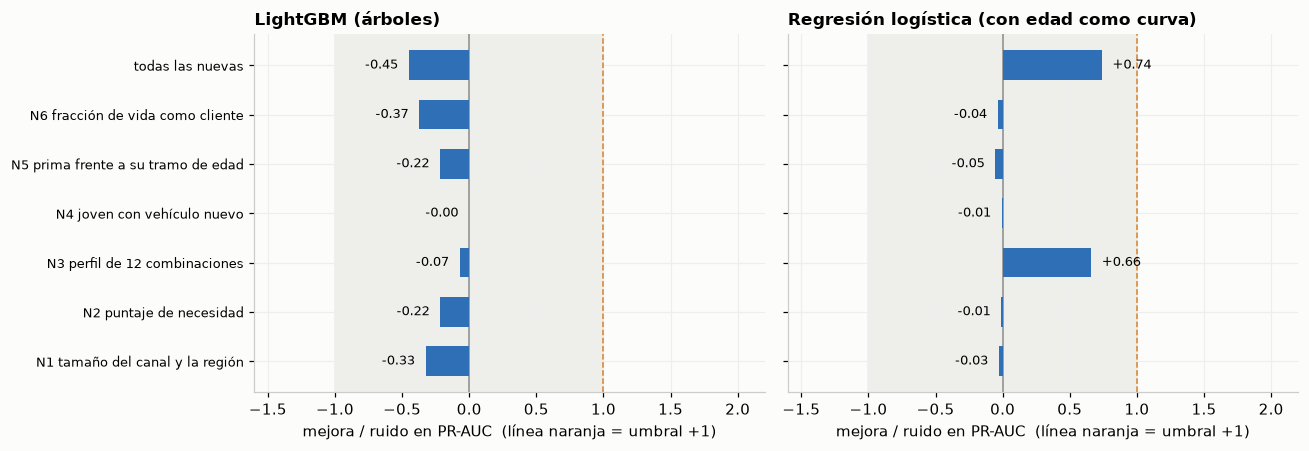

Guardado en reports/04_features_tabla_nuevas.csv: 16 filas.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
order2 = list(NEW_LABELS.values()) + ["todas las nuevas"]
for ax, (model_name, title) in zip(axes, [("lightgbm", "LightGBM (árboles)"), ("regresion_logistica", "Regresión logística (con edad como curva)")]):
    t = tables2[model_name]
    vals = [t.loc[v, "mejora / ruido (PR-AUC)"] for v in order2]
    ax.axvspan(-1, 1, color="#eeeeea", zorder=0)
    ax.axvline(0, color=GRAY, lw=1)
    ax.barh(range(len(order2)), vals, color=[ORANGE if v > 1 else BLUE for v in vals], height=0.6, zorder=2)
    for i, v in enumerate(vals):
        ax.text(v + (0.08 if v >= 0 else -0.08), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5)
    ax.axvline(1, color=ORANGE, lw=1, ls="--")
    ax.set_yticks(range(len(order2)))
    ax.set_yticklabels(order2, fontsize=8.5)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("mejora / ruido en PR-AUC  (línea naranja = umbral +1)")
    ax.set_xlim(-1.6, 2.2)
plt.tight_layout()
plt.show()

export2 = [{"modelo": m, "variante": v, "columnas_que_agrega": added_columns[(m, v)], "pr_auc": f["pr_auc"].mean(), "pr_auc_ruido": f["pr_auc"].std(ddof=1),
            "costo": f["cost"].mean(), "log_loss": f["log_loss"].mean(), "roc_auc": f["roc_auc"].mean()} for (m, v), f in results2.items()]
pd.DataFrame(export2).round(5).to_csv(ROOT / "reports" / "04_features_tabla_nuevas.csv", index=False)
print("Guardado en reports/04_features_tabla_nuevas.csv:", len(export2), "filas.")

### 9.2.1 Lectura: ninguna variable nueva cumple la regla

**LightGBM (árboles): todas quedan por debajo de la referencia.** Entre **-0,45 y 0,00** veces el ruido, ninguna gana en más de 2 de los 5 pliegues, y la combinación de las seis es la que más baja (**-0,45**, PR-AUC 0,3698 frente a 0,3715). El costo no se mueve (entre 0,3248 y 0,3256 frente a 0,3252): **seis variables más, cero beneficio de negocio**.

**Regresión logística: solo hay una señal tímida.**
- **N3 (perfil de 12 combinaciones)** sube la PR-AUC de 0,3562 a 0,3573: **+0,66 veces el ruido**, gana en 4 de 5 pliegues y mejora un poco el log loss (0,2665 → 0,2663). Es la **mejor de las seis, pero no llega a +1** y el costo **no cambia** (0,3271 frente a 0,3272).
- **Las seis juntas** dan +0,74 (PR-AUC 0,3575, 5 de 5 pliegues): consistente, pero **por debajo del umbral** y sin efecto en el costo.
- Las otras cinco quedan en el ruido (entre -0,05 y 0,00).

**Decisión según la regla (R1: mejora / ruido > 1 y 4 de 5 pliegues):** las **seis se descartan**. Se deja **N3 en observación**: si la regresión llega a ser finalista del torneo, vale la pena repetir la prueba, porque es la única con una mejora pequeña pero consistente. No justifica por sí sola 12 columnas más.

**Por qué no aportan, aunque en el EDA (sección 4.2) muestren señal clara:**
- **N2 y N3 son funciones exactas de tres columnas que el modelo ya tiene** (`Previously_Insured`, `Vehicle_Damage`, `Vehicle_Age`). Un árbol las reconstruye solo; la regresión ya captura casi todo con las tres por separado.
- **N4** reexpresa la edad y la antigüedad del vehículo, que tienen correlación de 0,82 entre sí.
- **N6** es en esencia `1 / edad`: su señal aparente (correlación -0,07, frente a -0,001 de `Vintage`) viene de la edad, que el modelo ya usa.
- **N1** identifica el canal (el canal más masivo, el 152, es el que menos convierte): el modelo ya conoce el canal.
- **N5** es más débil que la prima original (0,022 frente a 0,034 de correlación).

> **Una señal descriptiva clara no es valor incremental.** Una variable derivada de otras que el modelo ya tiene solo sirve si le entrega **algo que el modelo no podía construir solo**. Aquí ninguna lo hizo.

### 9.2.2 Qué significa para el negocio: el techo está en los datos, no en el modelado

Con 10 variables, el costo ya está en **0,325 por cliente** y agregar variables derivadas **no lo baja**. Es una conclusión útil: **dejar de invertir tiempo en inventar columnas** a partir de las mismas respuestas y **decidir qué datos nuevos conviene pedir**.

**Propuesta de datos nuevos para evaluar [DECIDE EL GRUPO]**. Son **hipótesis**: no se pueden medir con este dataset y deben validarse con la aseguradora antes de prometer nada.

| Prioridad | Dato nuevo | Por qué podría mover la aguja | Disponibilidad | Riesgo o cuidado |
|---|---|---|---|---|
| **1** | **Historial de contactos** (cuántas veces se llamó antes, cuándo, qué respondió) | En venta cruzada suele ser de los predictores más fuertes: quien rechazó tres veces no es igual a quien nunca fue contactado | Alta si hay CRM | Evitar sobrecontactar; privacidad |
| **2** | **Fecha de vencimiento del seguro de vehículo actual** (para quien ya tiene) | El 46 % ya asegurado compra casi nunca (0,1 %), pero **cerca de la renovación** es el momento de cambiar: hoy se descarta a todo ese grupo | Media (depende de la aseguradora) | Usar solo datos que el cliente haya autorizado |
| **3** | **Tiempo desde el último siniestro y su monto** (en vez de "tuvo daño: sí/no") | El daño es la 2.ª variable más fuerte; **un daño reciente y costoso** probablemente pesa más que uno antiguo y leve | Alta si hay reclamos | Datos sensibles de salud del vehículo |
| **4** | **Número de vehículos y de pólizas del hogar** | Quien tiene varias pólizas ya es cliente comprometido con la aseguradora | Media | Ninguno especial |
| **5** | **Canal y horario preferidos de contacto** | Cambia **cómo** se llama, no **a quién**; puede subir la tasa de contestación | Baja a media | Consentimiento del cliente |
| **6** | **Ingreso o nivel socioeconómico** | Capacidad de pago | Baja | **Alto riesgo de equidad y de reclamo regulatorio**; solo con revisión legal |

**Cómo se mediría:** se agrega cada dato al dataset, se repite este mismo experimento (mismos pliegues, mismos modelos, misma regla) y se decide con la **mejora sobre el ruido**. La inversión en conseguir el dato solo se justifica si la mejora supera el costo de obtenerlo y mantenerlo.

## 10. Supuestos, riesgos y qué se lleva el pipeline final

### 10.1 Supuestos y riesgos (propuesta para el equipo)

| # | Supuesto o riesgo | Impacto si falla | Mitigación propuesta | Responsable |
|---|---|---|---|---|
| 1 | **R = 5** (no llamar a un comprador cuesta 5 veces una llamada inútil) es una hipótesis. Fija el umbral de contacto en 16,7 % | Cambia el costo absoluto y el umbral; **no** el orden entre variantes | Confirmar con la aseguradora el margen de una venta y el costo de una llamada | Negocio |
| 2 | La app puede pedir y validar `Previously_Insured`, `Vehicle_Damage`, `Vehicle_Age`, `Age`, región, canal y prima | Si algo no se puede pedir al llamar, el modelo no es usable | Validar con ventas que el vendedor conoce estos 7 datos **antes** de la llamada (regla R2) | Negocio |
| 3 | Retirar `Gender` no garantiza equidad: `Age` y la región pueden actuar como sustitutos | Un modelo "sin género" aún podría tratar distinto a hombres y mujeres | Medir recall y tasa de contacto por género y por tramo de edad en la validación (etapa 7) | Datos y Legal |
| 4 | Los canales cambian con el tiempo (en `test.csv` ya aparecen dos que no estaban en el entrenamiento) | Un canal nuevo recibiría trato arbitrario | El agrupamiento envía canales desconocidos a "otros"; revisar la lista de canales cada trimestre | Datos |
| 5 | La prima se usa como llega: el 17 % vale exactamente 2.630 (parece un mínimo impuesto) | Si la política de precios cambia, la señal cambia | Vigilar la distribución de la prima en producción; reentrenar si cambia el mínimo | Datos |
| 6 | Todas las cifras salen de **un solo dataset histórico**: el modelo asume que los clientes futuros se parecen a estos | Si cambia el perfil de cliente, el rendimiento cae | Medir periódicamente la tasa real de aceptación contra la que predice el modelo | Datos y Negocio |
| 7 | Las cifras de la prueba cerrada **no se conocen**: aquí todo es validación cruzada | La cifra definitiva puede diferir | Abrir la prueba **una sola vez**, en la etapa 7 | Datos |

### 10.2 Lo que se lleva el pipeline final

**Variables de entrada que debe dar la app (7):** `Previously_Insured`, `Vehicle_Damage`, `Vehicle_Age`, `Age`, `Region_Code`, `Policy_Sales_Channel`, `Annual_Premium`
(más `Premium_is_minimum`, que se **calcula sola** a partir de la prima).

**Se retiran del modelo:** `Gender`, `Vintage`, `Driving_License` (sin costo medible) e `id` (solo identifica).

**Transformaciones dentro del `Pipeline` (aprenden solo del entrenamiento):**
- Canales y regiones con menos de 100 clientes → una categoría "otros"; canales nuevos → "otros".
- Para la **regresión logística**: edad como curva suave, y variables numéricas escaladas.
- Para **LightGBM**: sin transformaciones adicionales.

**Dónde está el código:** `src/proyecto/features/engineering.py`, `src/proyecto/models/train.py` y `src/proyecto/models/metrics.py`, con sus pruebas en `tests/`.

**Lo que NO se lleva y por qué:** recorte de la prima, segmento comercial como variable, tasa histórica de región y canal, prima relativa a la región (sección 9) y las seis variables derivadas de la segunda ronda (sección 9.2). Solo el perfil de 12 combinaciones queda **en observación** por si la regresión llega a ser finalista. Se conservan **documentadas** en `reports/04_features_tabla.csv`.

## 11. Pruebas automáticas

In [15]:
import subprocess

res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", "tests/test_cleaning.py", "tests/test_split.py",
                      "tests/test_features.py", "tests/test_models.py"], cwd=ROOT, capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
assert res.returncode == 0, res.stdout[-2000:]

69 passed in 9.34s


## Entregable de esta etapa

- [x] Cada idea tiene su fila con **mejora / ruido** y una decisión escrita (sección 9).
- [x] Todas las variantes se midieron con **los mismos 5 pliegues** de la etapa 3.
- [x] Ninguna variable usa información que no se conoce **al llamar**; se comprobó además que no hay fuga (etiquetas barajadas).
- [x] El código reutilizable está en `src/proyecto/features/` y `src/proyecto/models/`, con pruebas; el notebook solo lo llama.
- [x] `reports/04_features.md` y `reports/04_features_tabla.csv` completados.
- [ ] El grupo confirma las reglas R1-R5 y los parámetros marcados **[DECIDE EL GRUPO]** (R = 5, tamaño de campaña).
- [ ] Negocio y Legal cierran las decisiones que les corresponden (retirar `Gender`, qué datos puede pedir la app).
- [ ] Revisión del código con `material-del-curso/kit/checklist-revision-ia.md`.

**Siguiente:** `05_torneo.ipynb`: se comparan modelos con las variables aquí decididas.